My Setup

In [ ]:
import os
import cv2
import torch
import random
import numpy as np
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [ ]:
!pip install plotly
import plotly.graph_objects as go


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
DATASET_PATH = "/content/drive/MyDrive/tennis - data"

classes = ["Backhand", "Forehand", "NoStroke", "Serves"]
class_to_idx = {cls: idx for idx, cls in enumerate(classes)}

print("Class mapping:", class_to_idx)
print("Dataset path:", DATASET_PATH)




Class mapping: {'Backhand': 0, 'Forehand': 1, 'NoStroke': 2, 'Serves': 3}
Dataset path: /content/drive/MyDrive/tennis - data


In [ ]:
for cls in classes:
    folder = os.path.join(DATASET_PATH, cls)
    print(cls, "→", len(os.listdir(folder)), "videos")


Backhand → 21 videos
Forehand → 21 videos
NoStroke → 41 videos
Serves → 21 videos


In [ ]:
import cv2
import matplotlib.pyplot as plt
import random

def show_sample_frames_per_class(
    dataset_path,
    classes,
    num_frames=4,
    resize=(224, 224)
):
    fig, axes = plt.subplots(len(classes), num_frames, figsize=(num_frames * 3, len(classes) * 3))

    for row, cls in enumerate(classes):
        cls_folder = os.path.join(dataset_path, cls)
        video_files = [f for f in os.listdir(cls_folder) if f.endswith(".mp4")]

        video_path = os.path.join(cls_folder, random.choice(video_files))
        cap = cv2.VideoCapture(video_path)

        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        frame_indices = [int(i * total_frames / num_frames) for i in range(num_frames)]

        frames = []
        for idx in frame_indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
            ret, frame = cap.read()
            if ret:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frame = cv2.resize(frame, resize)
                frames.append(frame)
        cap.release()

        for col in range(num_frames):
            ax = axes[row, col]
            ax.imshow(frames[col])
            ax.axis("off")
            if col == 0:
                ax.set_ylabel(cls, fontsize=12)

    plt.suptitle("Sample Frames from Each Class", fontsize=14)
    plt.tight_layout()
    plt.show()


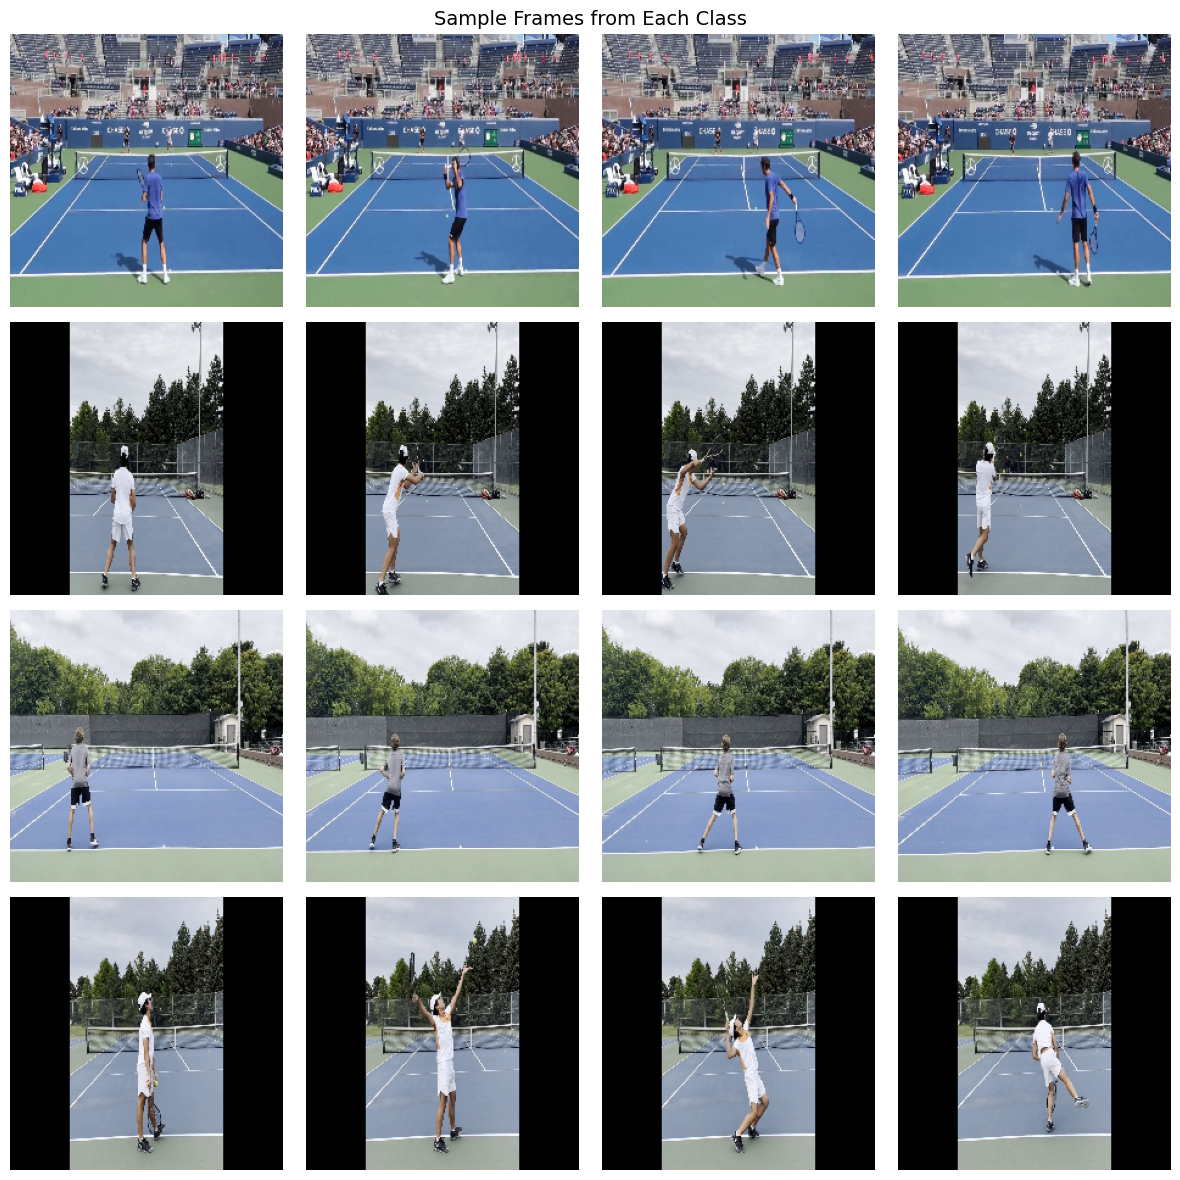

In [ ]:
show_sample_frames_per_class(
    DATASET_PATH,
    classes,
    num_frames=4
)


In [ ]:
def load_video_frames(path, num_frames=16, resize=(112, 112)):
    """
    Extracts 'num_frames' evenly spaced frames from a video
     Then returns: numpy array of shape (num_frames, H, W, 3)
    """

    cap = cv2.VideoCapture(path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # we want evenly spaced frame numbers - uniform sampling
    indices = np.linspace(0, total_frames - 1, num_frames).astype(int)

    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()

        if not ret:
            continue

        # we are just matching pytorch colour format nothing special
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # we need to resize as neural networks require fixed input dimensions
        frame = cv2.resize(frame, resize)

        # Normalisation - stabalises gradient descent
        frame = frame.astype(np.float32) / 255.0

        frames.append(frame)

    cap.release()

    # if video is too short can duplicate
    if len(frames) < num_frames:
        while len(frames) < num_frames:
            frames.append(frames[-1])

    return np.array(frames)


In [ ]:
class TennisVideoDataset(Dataset):
    def __init__(self, video_paths, labels, num_frames=16):
        """
        This is the custom dataset for the tennis stroke videos
        the class recieves a list of videos
        so when an item is requested it loads the corresponding videos and
        Returns the frames and their label
        """
        self.video_paths = video_paths
        self.labels = labels
        self.num_frames = num_frames


        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((112, 112)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.video_paths)

    def __getitem__(self, idx):
        video_path = self.video_paths[idx]
        label = self.labels[idx]

        # Extracts a fixed set of frames
        frames = load_video_frames(video_path, num_frames=self.num_frames)



        processed_frames = []
        for f in frames:
            f = self.transform(f)
            processed_frames.append(f)

        # Convert list → tensor
        frames = torch.stack(processed_frames)   # (T, C, H, W)

        return frames, label



In [ ]:
from sklearn.model_selection import train_test_split

# we start by collecting all the videos and images
all_video_paths = []
all_labels = []

for cls in classes:
    folder = os.path.join(DATASET_PATH, cls)
    for fname in os.listdir(folder):
        if fname.endswith(".mp4"):
            all_video_paths.append(os.path.join(folder, fname))
            all_labels.append(class_to_idx[cls])

# we split this way -our original dataset is imbalanced
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_video_paths,
    all_labels,
    test_size=0.30,
    stratify=all_labels,
    random_state=42
)

# Then split temp equally into validation and test sets
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

print("Training videos:", len(train_paths))
print("Validation videos:", len(val_paths))
print("Test videos:", len(test_paths))


Training videos: 70
Validation videos: 15
Test videos: 15


In [ ]:
batch_size = 4  # small because each sample contains 16 frames

train_dataset = TennisVideoDataset(train_paths, train_labels, num_frames=16)
val_dataset   = TennisVideoDataset(val_paths,  val_labels,  num_frames=16)
test_dataset  = TennisVideoDataset(test_paths, test_labels, num_frames=16)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

print("DataLoaders created successfully.")


DataLoaders created successfully.


1ST MODEL: CNN

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(SimpleCNN, self).__init__()

        # 1st conv block - transforms RGB images into 16 learned feature maps
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        # now we increase 16 to 32 and decrease spatial resolution
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        #extracts more features such as edges/corners/textures
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # then we transform learned conv features into a 128 dimensional vector
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 14 * 14, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        """
        x shape: (batch, frames, C, H, W)
        We apply the CNN to each frame - then average predictions.
        """
        batch_size, num_frames, C, H, W = x.shape

        frame_logits = []

        for i in range(num_frames):
            out = self.features(x[:, i])
            out = self.classifier(out)
            frame_logits.append(out)

        # temporal average pooling - avg frame predictions - get single predict
        video_logits = torch.stack(frame_logits, dim=0).mean(dim=0)

        return video_logits


In [ ]:
model = SimpleCNN(num_classes=4).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

num_epochs = 5

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []

    for frames, labels in loader:
        frames = frames.to(device)
        labels = labels.to(device)


        optimizer.zero_grad()

        outputs = model(frames)
        #produces logits per video
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()
        #updates all weights

        total_loss += loss.item()

        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    return total_loss / len(loader), accuracy


def validate_one_epoch(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for frames, labels in loader:
            frames = frames.to(device)
            labels = labels.to(device)

            outputs = model(frames)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    return total_loss / len(loader), accuracy


TRAINING CNN

In [ ]:
train_losses = []
val_losses = []
train_accs = []
val_accs = []

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = validate_one_epoch(model, val_loader, criterion)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)


    print(epoch+1, round(train_acc,3), round(val_acc,3))


/tmp/ipython-input-1350026727.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)
/tmp/ipython-input-1350026727.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)


1 0.343 0.667


/tmp/ipython-input-1350026727.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)
/tmp/ipython-input-1350026727.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)


2 0.529 0.6


/tmp/ipython-input-1350026727.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)
/tmp/ipython-input-1350026727.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)


3 0.6 0.867


/tmp/ipython-input-1350026727.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)
/tmp/ipython-input-1350026727.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)


4 0.8 0.8


/tmp/ipython-input-1350026727.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)
/tmp/ipython-input-1350026727.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)


5 0.786 0.867


In [ ]:
torch.save(model.state_dict(), "/content/drive/MyDrive/tennis - data/baseline_simplecnn.pth")


In [ ]:
import os
os.listdir("/content/drive/MyDrive/tennis - data")


['FH_3.mp4',
 'FH_7.mp4',
 'FH_9.mp4',
 'FH_10.mp4',
 'FH_11.mp4',
 'FH_13.mp4',
 'FH_14.mp4',
 'FH_16.mp4',
 'FH_15.mp4',
 'FH_17.mp4',
 'FH_18.mp4',
 'FH_19.mp4',
 'FH_20.mp4',
 'FH_1.mp4',
 'FH_12.mp4',
 'FH_2.mp4',
 'FH_4.mp4',
 'FH_5.mp4',
 'FH_6.mp4',
 'FH_8.mp4',
 'Backhand',
 'Forehand',
 'NoStroke',
 'Serves',
 'baseline_simplecnn.pth']

  EVALUATION ON CNN

In [ ]:
# next step is to evaluate CNN on test set
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for frames, labels in test_loader:
        frames = frames.to(device)
        labels = labels.to(device)

        outputs = model(frames)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)
print("test accuracy:", test_acc)


test accuracy: 0.8


In [ ]:
cm = confusion_matrix(all_labels, all_preds)
cm


array([[3, 0, 0, 0],
       [0, 0, 2, 1],
       [0, 0, 6, 0],
       [0, 0, 0, 3]])

MOVING ON TO 2ND MODEL

In [ ]:
# Here I have chosen to use feature extractor -  ResNet18 pretrained on ImageNet
class ResNetFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

        # this line removes the final classification layer
        self.feature_extractor = nn.Sequential(*list(resnet.children())[:-1])

        # output size is 512 - features
        self.out_dim = 512

        # freeze resnet weights - this just speeds up training
        for param in self.feature_extractor.parameters():
            param.requires_grad = False
        self.feature_extractor.eval()

    def forward(self, x):

        x = self.feature_extractor(x)
        x = x.view(x.size(0), -1)
        return x


In [ ]:
class ResNetLSTM(nn.Module):
    def __init__(self, hidden_size=256, num_layers=1, num_classes=4):
        super().__init__()

        self.feature_extractor = ResNetFeatureExtractor()

        self.lstm = nn.LSTM(
            input_size=self.feature_extractor.out_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, frames):

        b, t, c, h, w = frames.size()

        # merging batch with time
        frames = frames.view(b * t, c, h, w)


        feats = self.feature_extractor(frames)

        # reshape  - back to sequence
        feats = feats.view(b, t, -1)

        lstm_out, _ = self.lstm(feats)
        final_feature = lstm_out[:, -1, :]
        logits = self.classifier(final_feature)
        return logits


In [ ]:
model = ResNetLSTM(num_classes=4).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
#the learning rate is lower than the base as we know LTSMs are more sensitive

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 139MB/s]


TRAINING 2ND MODEL

In [ ]:

#using the same training loop we used for the baseline
#we will just make the epoch range to 5 just to see
train_losses = []
val_losses = []
train_accs = []
val_accs = []

for epoch in range(5):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = validate_one_epoch(model, val_loader, criterion)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(epoch+1, train_acc, val_acc)


/tmp/ipython-input-1350026727.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)
/tmp/ipython-input-1350026727.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)


1 0.38571428571428573 0.4


/tmp/ipython-input-1350026727.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)
/tmp/ipython-input-1350026727.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)


2 0.4857142857142857 0.5333333333333333


/tmp/ipython-input-1350026727.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)
/tmp/ipython-input-1350026727.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)


3 0.7 0.8666666666666667


/tmp/ipython-input-1350026727.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)
/tmp/ipython-input-1350026727.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)


4 0.7 0.8666666666666667


/tmp/ipython-input-1350026727.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)
/tmp/ipython-input-1350026727.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)


5 0.8 0.8666666666666667


In [ ]:
torch.save(model.state_dict(), "/content/drive/MyDrive/tennis - data/advanced_resnet_lstm.pth")


EVALUATING 2ND MODEL

In [ ]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for frames, labels in test_loader:
        frames = frames.to(device)
        labels = labels.to(device)

        outputs = model(frames)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)
print("test acc:", test_acc)


test acc: 0.8666666666666667


In [ ]:
cm = confusion_matrix(all_labels, all_preds)
cm


array([[3, 0, 0, 0],
       [0, 1, 1, 1],
       [0, 0, 6, 0],
       [0, 0, 0, 3]])

In [ ]:
print(classification_report(all_labels, all_preds, target_names=classes))


              precision    recall  f1-score   support

    Backhand       1.00      1.00      1.00         3
    Forehand       1.00      0.33      0.50         3
    NoStroke       0.86      1.00      0.92         6
      Serves       0.75      1.00      0.86         3

    accuracy                           0.87        15
   macro avg       0.90      0.83      0.82        15
weighted avg       0.89      0.87      0.84        15



In [ ]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    y=train_accs,
    mode='lines+markers',
    name='Train Accuracy',
    line=dict(color='#ff8fb1', width=3),
    marker=dict(color='#ffb3c6', size=8)
))

fig.add_trace(go.Scatter(
    y=val_accs,
    mode='lines+markers',
    name='Validation Accuracy',
    line=dict(color='#ff4d88', width=3),
    marker=dict(color='#ff8fb1', size=8)
))

fig.update_layout(
    title="<b>Accuracy Over Epochs</b>",
    xaxis_title="Epoch",
    yaxis_title="Accuracy",
    template="simple_white",
    font=dict(family="Arial", size=14, color="#333"),
    plot_bgcolor="#fffafa",
    paper_bgcolor="white",
    legend=dict(
        bgcolor="rgba(255, 240, 245, 0.6)",
        bordercolor="#ffb3c6",
        borderwidth=1
    )
)

fig.show()



In [ ]:

fig = go.Figure()

fig.add_trace(go.Scatter(
    y=train_losses,
    mode='lines+markers',
    name='Train Loss',
    line=dict(color='#ff9ebb', width=3),
    marker=dict(color='#ffcad4', size=8)
))

fig.add_trace(go.Scatter(
    y=val_losses,
    mode='lines+markers',
    name='Validation Loss',
    line=dict(color='#ff5c8a', width=3),
    marker=dict(color='#ff9ebb', size=8)
))

fig.update_layout(
    title="<b>Loss Over Epochs</b>",
    xaxis_title="Epoch",
    yaxis_title="Loss",
    template="simple_white",
    font=dict(family="Arial", size=14, color="#333"),
    plot_bgcolor="#fffafa",
    paper_bgcolor="white",
    legend=dict(
        bgcolor="rgba(255, 240, 245, 0.6)",
        bordercolor="#ffb3c6",
        borderwidth=1
    )
)

fig.show()


MY FINAL MODEL: ATTEMPT 1

In [ ]:
class ResNetAvgPool(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.feature_extractor = ResNetFeatureExtractor()
        self.classifier = nn.Linear(self.feature_extractor.out_dim, num_classes)

    def forward(self, frames):
        B, T, C, H, W = frames.size()
        frames = frames.view(B * T, C, H, W)

        feats = self.feature_extractor(frames)
        feats = feats.view(B, T, -1)

        # now temporal avg pooling
        video_feats = feats.mean(dim=1)

        out = self.classifier(video_feats)
        return out



In [ ]:
model = ResNetAvgPool(num_classes=4).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(5):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = validate_one_epoch(model, val_loader, criterion)
    print(epoch+1, train_acc, val_acc)


1 0.38571428571428573 0.5333333333333333


In [ ]:
criterion = torch.nn.CrossEntropyLoss()


In [ ]:
import os

SAVE_DIR = "/content/drive/MyDrive/tennis - data/Models"
os.makedirs(SAVE_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(SAVE_DIR, "resnet_avgpool_best.pth")


FINAL MODEL - TRAINING FOR LONGER

In [ ]:
EPOCHS = 15
best_val_acc = 0.0

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    train_loss, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion
    )
    val_loss, val_acc = validate_one_epoch(
        model, val_loader, criterion
    )

    print(
        f"Train acc: {train_acc:.3f} | "
        f"Val acc: {val_acc:.3f}"
    )


    if val_acc > best_val_acc:
        best_val_acc = val_acc

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_acc": val_acc
        }, BEST_MODEL_PATH)

        print(f" Saved new best model (val acc = {val_acc:.3f})")




Epoch 1/15
Train acc: 0.243 | Val acc: 0.267
 Saved new best model (val acc = 0.267)

Epoch 2/15
Train acc: 0.400 | Val acc: 0.333
 Saved new best model (val acc = 0.333)

Epoch 3/15
Train acc: 0.400 | Val acc: 0.400
 Saved new best model (val acc = 0.400)

Epoch 4/15
Train acc: 0.400 | Val acc: 0.400

Epoch 5/15
Train acc: 0.514 | Val acc: 0.467
 Saved new best model (val acc = 0.467)

Epoch 6/15
Train acc: 0.543 | Val acc: 0.467

Epoch 7/15
Train acc: 0.543 | Val acc: 0.467

Epoch 8/15
Train acc: 0.571 | Val acc: 0.467

Epoch 9/15
Train acc: 0.571 | Val acc: 0.667
 Saved new best model (val acc = 0.667)

Epoch 10/15
Train acc: 0.643 | Val acc: 0.733
 Saved new best model (val acc = 0.733)

Epoch 11/15
Train acc: 0.600 | Val acc: 0.733

Epoch 12/15
Train acc: 0.600 | Val acc: 0.667

Epoch 13/15
Train acc: 0.629 | Val acc: 0.667

Epoch 14/15
Train acc: 0.643 | Val acc: 0.733

Epoch 15/15
Train acc: 0.729 | Val acc: 0.733


In [ ]:
MODELS_DIR = "/content/drive/MyDrive/tennis - data/Models"



In [ ]:
import os
print(os.listdir(MODELS_DIR))


['resnet_avgpool_best.pth']


In [ ]:
checkpoint = torch.load(best_model_path, map_location=device)


In [ ]:
best_model = ResNetAvgPool(num_classes=4).to(device)


EVALUATION OF ATTEMPT 1

In [ ]:
best_model.load_state_dict(checkpoint["model_state_dict"])
best_model.eval()


ResNetAvgPool(
  (feature_extractor): ResNetFeatureExtractor(
    (feature_extractor): Sequential(
      (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (4): Sequential(
        (0): BasicBlock(
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu): ReLU(inplace=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
        (1): BasicBlock(
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
 

In [ ]:
print(
    f"Loaded model from epoch {checkpoint['epoch']} "
    f"with val acc {checkpoint['val_acc']:.3f}"
)


Loaded model from epoch 10 with val acc 0.733


In [ ]:
import torch
import numpy as np

all_preds = []
all_labels = []

best_model.eval()

with torch.no_grad():
    for videos, labels in test_loader:
        videos = videos.to(device)
        labels = labels.to(device)

        outputs = best_model(videos)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_preds)
print(cm)


[[2 0 1 0]
 [0 2 1 0]
 [0 0 6 0]
 [0 0 0 3]]


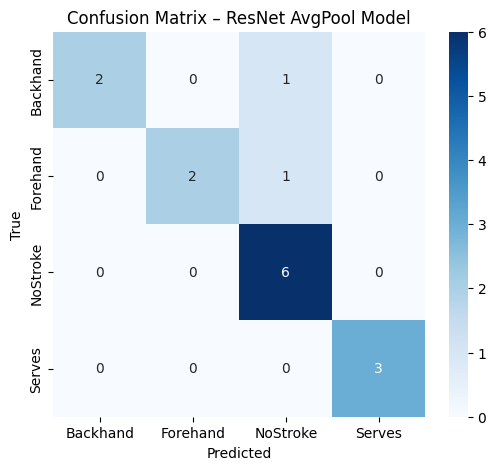

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

class_names = ["Backhand", "Forehand", "NoStroke", "Serves"]

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix – ResNet AvgPool Model")
plt.show()


In [ ]:

classes = ["Backhand", "Forehand", "NoStroke", "Serves"]
num_classes = len(classes)
print("num_classes =", num_classes)


num_classes = 4


VERSION 2

In [ ]:
class ResNetVideoClassifier_Attn(nn.Module):
    def __init__(self, num_classes, pretrained=True):
        super().__init__()
        base = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT if pretrained else None
        )
        self.feature_extractor = nn.Sequential(*list(base.children())[:-1])
        self.feature_dim = 512

        self.temporal_attn = nn.Sequential(
            nn.Linear(self.feature_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(self.feature_dim, num_classes)

    def forward(self, x):
        B, T, C, H, W = x.shape
        x = x.view(B * T, C, H, W)
        f = self.feature_extractor(x)
        f = f.view(B, T, self.feature_dim)

        w = self.temporal_attn(f)
        w = torch.softmax(w, dim=1)

        video_feat = (f * w).sum(dim=1)
        video_feat = self.dropout(video_feat)
        return self.fc(video_feat)


In [ ]:
attn_model = ResNetVideoClassifier_Attn(
    num_classes=num_classes,
    pretrained=True
).to(device)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 140MB/s]


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(attn_model.parameters(), lr=1e-4)

EPOCHS_FINAL = 20
best_val_f1 = -1
best_state = None


In [ ]:
from sklearn.metrics import f1_score

def validate_with_preds(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for frames, labels in loader:
            frames = frames.to(device)
            labels = labels.to(device)

            outputs = model(frames)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average="macro")

    return (
        total_loss / len(loader),
        accuracy,
        macro_f1,
        all_preds,
        all_labels,
    )


In [ ]:
BEST_MODEL_PATH = "resnet18_attention_best.pth"


FINAL MODEL TRAINING

In [ ]:
attn_model = ResNetVideoClassifier_Attn(
    num_classes=num_classes,
    pretrained=True
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(attn_model.parameters(), lr=1e-4)

EPOCHS = 15
best_val_f1 = -1.0
best_state = None

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    train_loss, train_acc = train_one_epoch(
        attn_model, train_loader, optimizer, criterion
    )

    val_loss, val_acc, val_macro_f1, val_preds, val_labels = validate_with_preds(
        attn_model, val_loader, criterion
    )

    print(
        f"Train acc: {train_acc:.3f} | "
        f"Val acc: {val_acc:.3f} | "
        f"Val macro F1: {val_macro_f1:.3f}"
    )

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_state = {
            "epoch": epoch + 1,
            "model_state_dict": attn_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_macro_f1": val_macro_f1
        }
        torch.save(best_state, BEST_MODEL_PATH)
        print(f"  Saved new best model (macro F1 = {val_macro_f1:.3f})")



Epoch 1/15
Train acc: 0.629 | Val acc: 0.867 | Val macro F1: 0.887
  Saved new best model (macro F1 = 0.887)

Epoch 2/15
Train acc: 0.786 | Val acc: 0.933 | Val macro F1: 0.931
  Saved new best model (macro F1 = 0.931)

Epoch 3/15
Train acc: 0.843 | Val acc: 0.933 | Val macro F1: 0.942
  Saved new best model (macro F1 = 0.942)

Epoch 4/15
Train acc: 0.829 | Val acc: 0.933 | Val macro F1: 0.942

Epoch 5/15
Train acc: 0.814 | Val acc: 0.933 | Val macro F1: 0.931

Epoch 6/15
Train acc: 0.900 | Val acc: 0.867 | Val macro F1: 0.887

Epoch 7/15
Train acc: 0.886 | Val acc: 0.933 | Val macro F1: 0.931

Epoch 8/15
Train acc: 0.957 | Val acc: 1.000 | Val macro F1: 1.000
  Saved new best model (macro F1 = 1.000)

Epoch 9/15
Train acc: 0.957 | Val acc: 0.933 | Val macro F1: 0.942

Epoch 10/15
Train acc: 0.986 | Val acc: 0.933 | Val macro F1: 0.931

Epoch 11/15
Train acc: 0.943 | Val acc: 0.867 | Val macro F1: 0.875

Epoch 12/15
Train acc: 0.857 | Val acc: 0.867 | Val macro F1: 0.887

Epoch 13/15


FINAL MODEL EVALUATION

In [ ]:

checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)

attn_model.load_state_dict(checkpoint["model_state_dict"])
attn_model.eval()

print("Loaded model from epoch", checkpoint["epoch"])
print("Best validation macro F1:", checkpoint["val_macro_f1"])


Loaded model from epoch 8
Best validation macro F1: 1.0


In [ ]:
test_loss, test_acc, test_macro_f1, test_preds, test_labels = validate_with_preds(
    attn_model, test_loader, criterion
)

print(f"Test Accuracy: {test_acc:.3f}")
print(f"Test Macro F1: {test_macro_f1:.3f}")


Test Accuracy: 0.933
Test Macro F1: 0.942


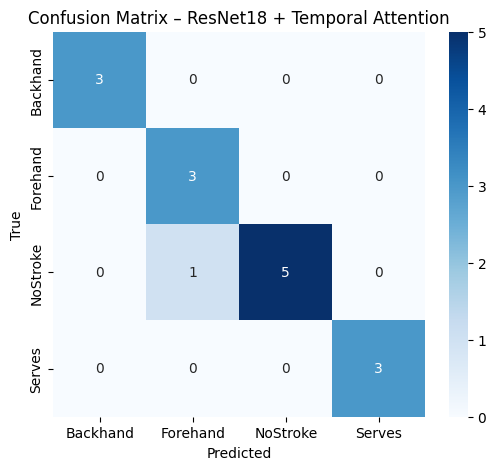

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(test_labels, test_preds)
class_names = ["Backhand", "Forehand", "NoStroke", "Serves"]

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix – ResNet18 + Temporal Attention")
plt.show()


In [ ]:
print(classification_report(test_labels, test_preds, target_names=class_names))


              precision    recall  f1-score   support

    Backhand       1.00      1.00      1.00         3
    Forehand       0.75      1.00      0.86         3
    NoStroke       1.00      0.83      0.91         6
      Serves       1.00      1.00      1.00         3

    accuracy                           0.93        15
   macro avg       0.94      0.96      0.94        15
weighted avg       0.95      0.93      0.94        15



In [ ]:
import os

MODELS_DIR = "/content/drive/MyDrive/tennis - data/Models"
os.makedirs(MODELS_DIR, exist_ok=True)

ATTN_SAVE_PATH = os.path.join(MODELS_DIR, "resnet18_attention_best.pth")


In [ ]:
torch.save(attn_model.state_dict(), ATTN_SAVE_PATH)
print("Saved attention model to:", ATTN_SAVE_PATH)


Saved attention model to: /content/drive/MyDrive/tennis - data/Models/resnet18_attention_best.pth


In [ ]:
os.listdir(MODELS_DIR)


['resnet_avgpool_best.pth', 'resnet18_attention_best.pth']

In [1]:
models = [
    "Baseline CNN",
    "ResNet + LSTM",
    "ResNet + Attention"
]

test_accuracy = [
    0.80,
    0.87,
    0.93
]

test_macro_f1 = [
    0.78,
    0.82,
    0.94
]


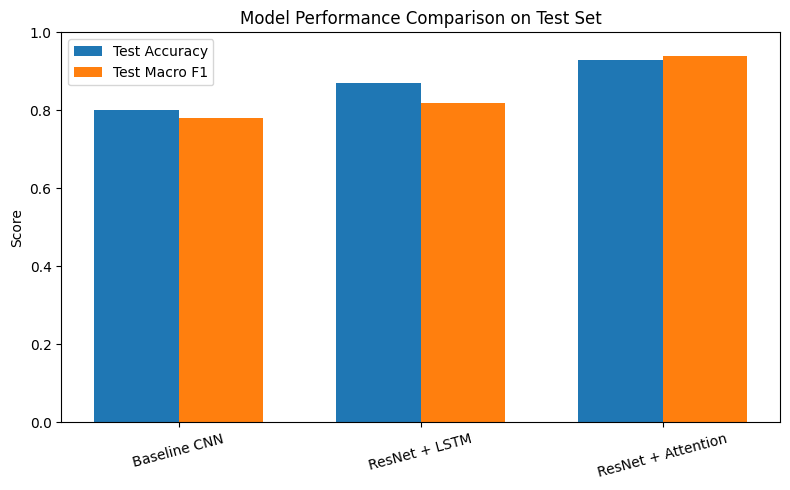

In [2]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, test_accuracy, width, label="Test Accuracy")
plt.bar(x + width/2, test_macro_f1, width, label="Test Macro F1")

plt.xticks(x, models, rotation=15)
plt.ylabel("Score")
plt.ylim(0, 1.0)
plt.title("Model Performance Comparison on Test Set")
plt.legend()

plt.tight_layout()
plt.show()
